# L17 - Lösung zu Aufgabe L17 - Remez-Entwurf (Tschebyscheff-Approximation)

Für die Lösung MATLAB `*.m` Dateiformat bitte [hier klicken](./l17.m).

## Teilaufgabe a: Filter entwerfen

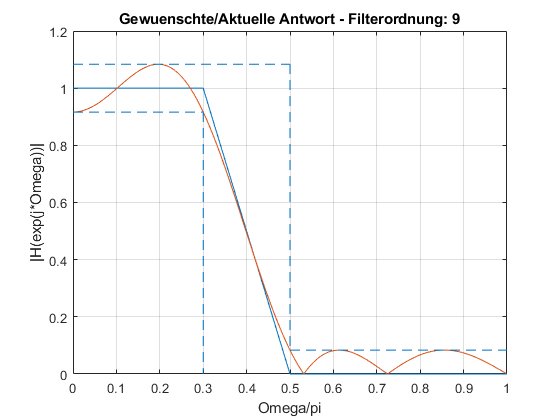

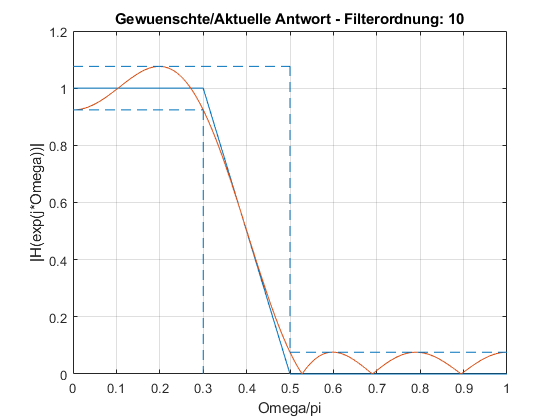

In [3]:
% ##############################################################################
% ##  Loesung:  Remez-Entwurf (Tschebyscheff-Approximation)                   ##
% ##                                                                          ##
% ##  Die funktion remez() wurde durch die in Matlab7 verwendete Funktion     ##
% ##  firpm() ersetzt!                                                        ##
% ##                                                                          ##
% ##############################################################################

% #####  Teilaufgabe a: Filter entwerfen  ######################################
f   = [0 0.3 0.5 1.0];     % Frequenzen der Sperr- und Durchlassbereiche
g   = [1 1 0 0];           % Impulsantwort
v_m = [9 10];              % Vektor mit den Filterordnungen

for m=v_m
    b = firpm(m,f,g);         % Filterentwurf nach Remez
    [H,W] = freqz(b,1,512);   % Berechnung des Frequenzgangs

    % # grafische Ausgabe # %
    string = sprintf('Gewuenschte/Aktuelle Antwort - Filterordnung: %d', m);
    figure;
    plot(f,g,W/pi,abs(H));
    line([0 0.3],[ 2-max(abs(H)) 2-max(abs(H))],'linestyle','--'); % Erzeugung
    line([0 0.5],[max(abs(H)) max(abs(H))],'linestyle','--');      % einer Linie
    line([0.5 1],[max(abs(H(400:length(H))))...                    % im Plot
        max(abs(H(400:length(H))))],'linestyle','--');
    line([0.3 0.3],[ 2-max(abs(H)) 0],'linestyle','--');
    line([0.5 0.5],[ max(abs(H)) max(abs(H(400:length(H))))],'linestyle','--');
    grid;
    xlabel('Omega/pi');
    ylabel('|H(exp(j*Omega))|');
    title(string);
end



##  Teilaufgabe b:  Frequenzgang wichten

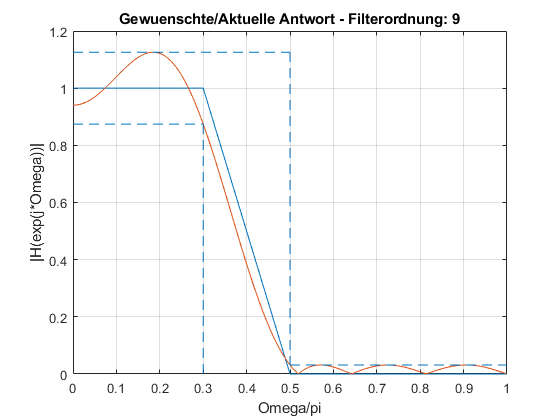

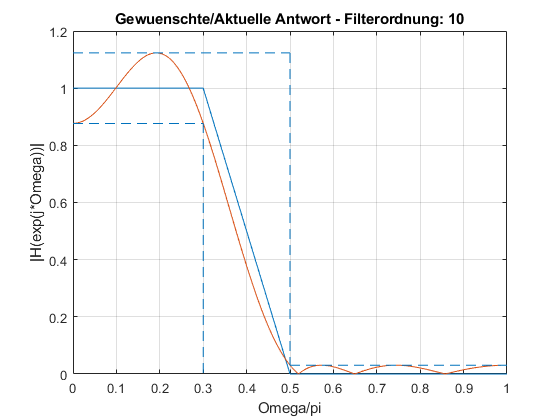

In [4]:
% #####  Teilaufgabe b: Frequenzgang wichten  ##################################
f   = [0 0.3 0.5 1.0];     % Frequenzen der Sperr- und Durchlassbereiche
g   = [1 1 0 0];           % Impulsantwort
w   = [ 0.5 2 ];           % Gewichtung des Durchlass- und Sperrbereichs
v_m = [9 10];              % Vektor mit den Filterordnungen

for m=v_m
    b = firpm(m,f,g,w);
    [H,W] = freqz(b,1,512);
    
    % # grafische Ausgabe # %
    string = sprintf('Gewuenschte/Aktuelle Antwort - Filterordnung: %d', m);
    figure; plot(f,g,W/pi,abs(H));
    line([0 0.3],[ 2-max(abs(H)) 2-max(abs(H))],'linestyle','--');
    line([0 0.5],[max(abs(H)) max(abs(H))],'linestyle','--');
    line([0.5 1],[max(abs(H(400:length(H)))) max(abs(H(400:length(H))))],...
        'linestyle','--');
    line([0.3 0.3],[ 2-max(abs(H)) 0],'linestyle','--');
    line([0.5 0.5],[ max(abs(H)) max(abs(H(400:length(H))))],'linestyle','--');
    grid;
    xlabel('Omega/pi');
    ylabel('|H(exp(j*Omega))|');
    title(string);
end



##  Teilaufgabe b:  Tiefpass-Bandpass Kombination

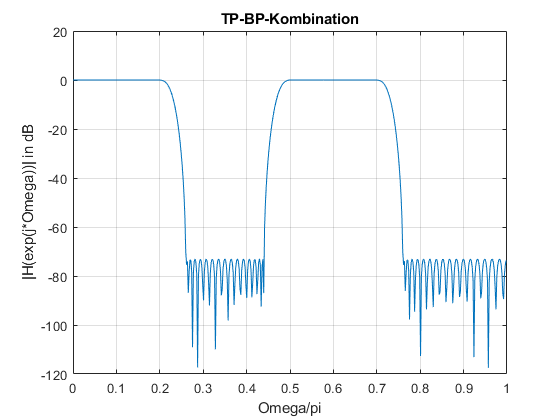

In [6]:
% #####  Teilaufgabe c: Tiefpass-Bandpass Kombination  #########################
f = [0 0.2 0.26 0.44 0.5 0.7 0.76 1]; % Vektor der Eckfrequenzen
g = [1  1   0    0    1   1   0   0]; % Vektor der Frequenzgaenge
w = [ 1       4         1       4];   % Vektor mit den Gewichten
m = 128;                              % Filterordnung
b = firpm(m,f,g,w); 
[H,W] = freqz(b,1,512);

% # grafische Ausgabe # %
figure;
plot(W/pi,20*log10(abs(H)) );
grid; 
xlabel('Omega/pi');
ylabel('|H(exp(j*Omega))| in dB');
title('TP-BP-Kombination');
% #####  EOF  #####